# Trabalho IAA009 – Deep Learning

## Exercício 1 – Classificação de Imagens com CNN (Base de Dados CIFAR-10)

## 1. Introdução

Neste exercício será implementada uma Rede Neural Convolucional (CNN)
para realizar a classificação de imagens utilizando a base de dados
CIFAR-10. A rede será implementada utilizando a biblioteca TensorFlow e a API
Keras, sendo posteriormente treinada e avaliada utilizando os conjuntos
de treinamento e teste da base CIFAR-10.

In [4]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Versão do TensorFlow:", tf.__version__)

Versão do TensorFlow: 2.20.0


## 2. Carregamento da base de dados

A base CIFAR-10 é composta por 60.000 imagens coloridas, divididas em
50.000 imagens para treinamento e 10.000 imagens para teste.

Cada imagem possui resolução de 32 × 32 pixels e três canais de cor (RGB).

A base possui 10 categorias de objetos: avião, automóvel, pássaro, gato,
veado, cachorro, sapo, cavalo, navio e caminhão.

In [5]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Dimensão X_train:", X_train.shape)
print("Dimensão y_train:", y_train.shape)
print("Dimensão X_test:", X_test.shape)
print("Dimensão y_test:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2096s 12us/step
Dimensão X_train: (50000, 32, 32, 3)
Dimensão y_train: (50000, 1)
Dimensão X_test: (10000, 32, 32, 3)
Dimensão y_test: (10000, 1)


## 3. Classes da CIFAR-10

A base CIFAR-10 possui 10 classes diferentes. Para facilitar a
interpretação dos resultados, será criada uma lista contendo o nome
correspondente a cada classe.

In [6]:
classes = [
    "avião",
    "automóvel",
    "pássaro",
    "gato",
    "veado",
    "cachorro",
    "sapo",
    "cavalo",
    "navio",
    "caminhão"
]

for i, classe in enumerate(classes):
    print(i, "-", classe)

0 - avião
1 - automóvel
2 - pássaro
3 - gato
4 - veado
5 - cachorro
6 - sapo
7 - cavalo
8 - navio
9 - caminhão


## 4. Visualização das imagens

A seguir são apresentadas algumas imagens pertencentes ao conjunto de
treinamento. As imagens são coloridas e possuem resolução de 32 × 32
pixels.

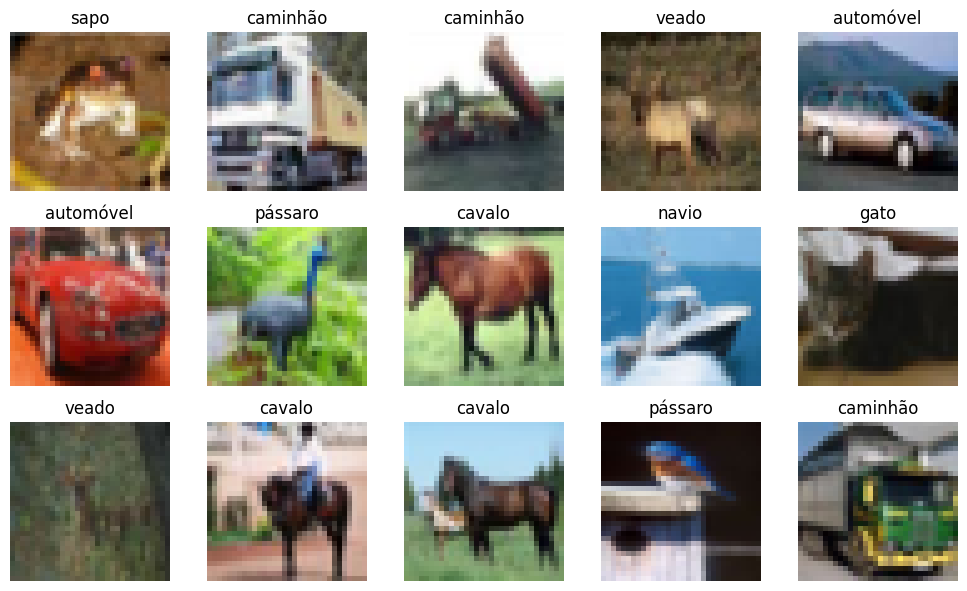

In [7]:
plt.figure(figsize=(10, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_train[i])
    plt.title(classes[y_train[i][0]])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 5. Pré-processamento dos dados

Os valores dos pixels das imagens originalmente estão no intervalo de
0 a 255. Para facilitar o treinamento da rede neural, os valores serão
normalizados para o intervalo entre 0 e 1.

Essa normalização é realizada dividindo cada valor de pixel por 255.

In [8]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Valor mínimo:", X_train.min())
print("Valor máximo:", X_train.max())

Valor mínimo: 0.0
Valor máximo: 1.0


## 6. Construção da Rede Neural Convolucional

Será utilizada uma arquitetura composta por duas camadas
convolucionais, cada uma seguida por uma camada de MaxPooling.

As camadas convolucionais utilizam a função de ativação ReLU e
realizam a extração de características das imagens.

As camadas de MaxPooling reduzem a dimensão espacial das
representações.

Após as camadas convolucionais e de pooling, a camada Flatten transforma
os mapas de características em um vetor unidimensional.

Em seguida, são utilizadas duas camadas densas (Dense). A última camada
possui 10 neurônios, correspondentes às 10 classes da base CIFAR-10,
utilizando a função Softmax para gerar as probabilidades de cada classe.

In [20]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(32, 32, 3)),

    # Primeiro estágio: Convolução + Pooling
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same",
        strides=1
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2),
        strides=2
    ),

    # Segundo estágio: Convolução + Pooling
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same",
        strides=1
    ),

    tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2),
        strides=2
    ),

    # Estágio de classificação
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        64,
        activation="relu"
    ),

    tf.keras.layers.Dense(
        10,
        activation="softmax"
    )
])

## 7. Arquitetura da rede

A arquitetura criada pode ser visualizada por meio do método
`summary()`, que apresenta as camadas da rede, as dimensões das
saídas e a quantidade de parâmetros treináveis.

In [21]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 282,250 (1.08 MB)

 Trainable params: 282,250 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

### 7.1 Dimensionalidade das camadas

A entrada da rede é uma imagem de tamanho **32 × 32 × 3**, correspondente à resolução das imagens do CIFAR-10 e aos três canais de cor RGB.

A primeira camada convolucional possui **32 filtros de tamanho 3 × 3**, com `padding="same"` e `stride=1`. Como o padding é `same` e o stride é 1, a dimensão espacial é preservada:

**32 × 32 × 3 → 32 × 32 × 32**

Em seguida, a camada `MaxPooling2D` utiliza uma janela de **2 × 2** e `stride=2`, reduzindo pela metade as dimensões espaciais:

**32 × 32 × 32 → 16 × 16 × 32**

A segunda camada convolucional possui **64 filtros de tamanho 3 × 3**, também utilizando `padding="same"` e `stride=1`. Dessa forma, as dimensões espaciais são mantidas:

**16 × 16 × 32 → 16 × 16 × 64**

O segundo `MaxPooling2D` reduz novamente as dimensões espaciais pela metade:

**16 × 16 × 64 → 8 × 8 × 64**

A camada `Flatten` transforma os mapas de características em um vetor:

**8 × 8 × 64 = 4096**

Assim, a sequência completa de dimensões é:

**32 × 32 × 3 → 32 × 32 × 32 → 16 × 16 × 32 → 16 × 16 × 64 → 8 × 8 × 64 → 4096 → 64 → 10**

### 7.2 Quantidade de parâmetros

A primeira camada convolucional possui 32 filtros de tamanho 3 × 3 e recebe 3 canais de entrada. Considerando também um bias para cada filtro:

**(3 × 3 × 3 + 1) × 32 = 896 parâmetros**

A segunda camada convolucional recebe 32 canais e possui 64 filtros:

**(3 × 3 × 32 + 1) × 64 = 18.496 parâmetros**

A camada `Dense` possui 4096 entradas e 64 neurônios:

**(4096 + 1) × 64 = 262.208 parâmetros**

Por fim, a última camada `Dense` possui 64 entradas e 10 neurônios:

**(64 + 1) × 10 = 650 parâmetros**

As camadas de `MaxPooling2D` e `Flatten` não possuem parâmetros treináveis.

Portanto, a rede possui:

**896 + 18.496 + 262.208 + 650 = 282.250 parâmetros treináveis.**

Esse valor corresponde ao total apresentado pelo comando `model.summary()`.


## 8. Compilação do modelo

Antes de realizar o treinamento, é necessário compilar o modelo. Nesta etapa, definimos o otimizador, a função de perda e a métrica utilizada para avaliar o desempenho da rede.

Será utilizado o otimizador Adam, a função de perda sparse categorical crossentropy, adequada para classificação multiclasse com rótulos inteiros, e a acurácia como métrica de avaliação.

In [22]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 9. Treinamento do modelo

Nesta etapa, a CNN será treinada utilizando o conjunto de treinamento do CIFAR-10.

O treinamento será realizado durante 10 épocas, utilizando lotes de 64 imagens. Além disso, 10% dos dados de treinamento serão utilizados para validação. Dessa forma, podemos acompanhar o desempenho do modelo tanto nos dados utilizados para treinamento quanto em dados separados para validação.

In [23]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 112ms/step - accuracy: 0.4518 - loss: 1.5262 - val_accuracy: 0.5620 - val_loss: 1.2316
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 78s 107ms/step - accuracy: 0.5970 - loss: 1.1427 - val_accuracy: 0.6204 - val_loss: 1.0859
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 84s 111ms/step - accuracy: 0.6478 - loss: 1.0020 - val_accuracy: 0.6476 - val_loss: 1.0400
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 77s 109ms/step - accuracy: 0.6831 - loss: 0.9092 - val_accuracy: 0.6908 - val_loss: 0.9178
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 74s 104ms/step - accuracy: 0.7030 - loss: 0.8491 - val_accuracy: 0.6996 - val_loss: 0.8872
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 81s 104ms/step - accuracy: 0.7222 - loss: 0.7975 - val_accuracy: 0.6914 - val_loss: 0.8980
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 76s 107ms/step - accuracy: 0.7393 - loss: 0.7503 - val_accuracy: 0.7158 - val_loss: 0.8721
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 75s 106ms/step - accuracy: 0.7551 - loss: 0

## 10. Avaliação do modelo no conjunto de teste

Após o treinamento, o modelo será avaliado utilizando o conjunto de teste do CIFAR-10. Esse conjunto contém 10.000 imagens que não foram utilizadas durante o treinamento ou a validação.

A avaliação permitirá verificar o desempenho final da CNN em imagens que ela não encontrou durante o processo de treinamento.

In [24]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Loss no conjunto de teste: {test_loss:.4f}")
print(f"Acurácia no conjunto de teste: {test_accuracy:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.6911 - loss: 0.9171
Loss no conjunto de teste: 0.9171
Acurácia no conjunto de teste: 0.6911


## 11. Visualização do treinamento

Para analisar a evolução do modelo durante o treinamento, serão apresentados dois gráficos: um para a acurácia e outro para a função de perda.

No gráfico de acurácia, serão comparados os resultados obtidos nos conjuntos de treinamento e validação. No gráfico de loss, será feita a mesma comparação.

Esses gráficos permitem observar a evolução do aprendizado e identificar possíveis sinais de overfitting, que ocorre quando o modelo melhora nos dados de treinamento, mas deixa de apresentar melhora equivalente nos dados de validação.

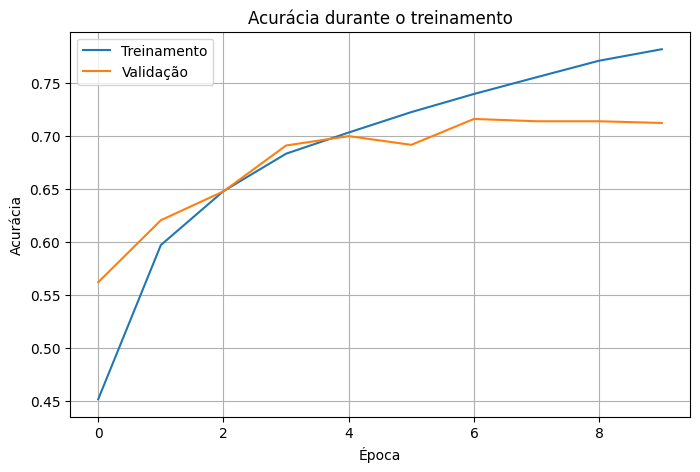

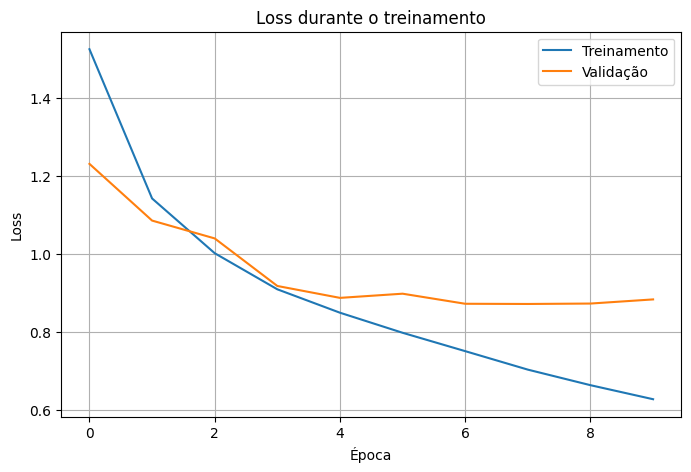

In [25]:
import matplotlib.pyplot as plt

# Acurácia
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Treinamento")
plt.plot(history.history["val_accuracy"], label="Validação")

plt.title("Acurácia durante o treinamento")
plt.xlabel("Época")
plt.ylabel("Acurácia")
plt.legend()
plt.grid(True)

plt.show()


# Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Treinamento")
plt.plot(history.history["val_loss"], label="Validação")

plt.title("Loss durante o treinamento")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.show()

## 12. Previsões do modelo

Nesta etapa, serão realizadas previsões utilizando algumas imagens do conjunto de teste.

Para cada imagem, será apresentada a classe verdadeira e a classe prevista pelo modelo. Dessa forma, podemos verificar visualmente alguns exemplos de acertos e erros realizados pela CNN.

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step


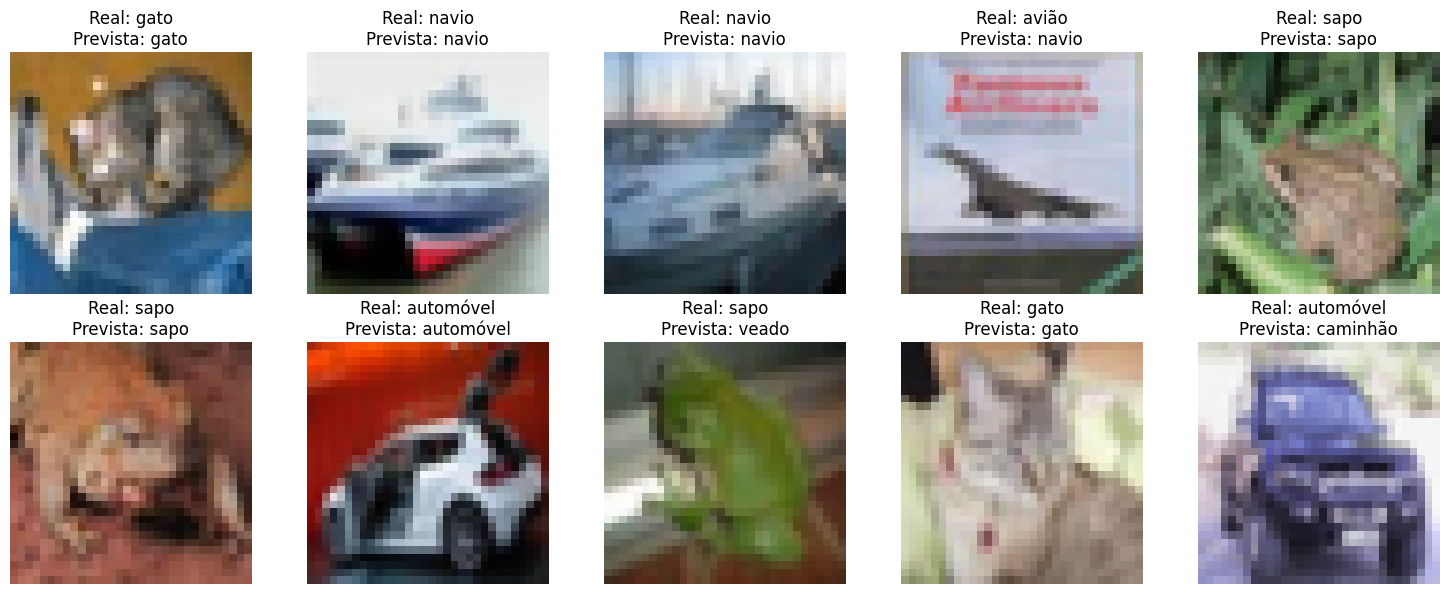

In [26]:
import numpy as np
import matplotlib.pyplot as plt

# Realiza as previsões para o conjunto de teste
predictions = model.predict(X_test)

# Obtém a classe com maior probabilidade para cada imagem
y_pred = np.argmax(predictions, axis=1)

# Nomes das classes
class_names = [
    "avião",
    "automóvel",
    "pássaro",
    "gato",
    "veado",
    "cachorro",
    "sapo",
    "cavalo",
    "navio",
    "caminhão"
]

# Exibe 10 imagens do conjunto de teste
plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i])

    verdadeira = class_names[y_test[i][0]]
    prevista = class_names[y_pred[i]]

    plt.title(
        f"Real: {verdadeira}\nPrevista: {prevista}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

## 13. Matriz de confusão

Para analisar de forma mais detalhada o desempenho da CNN, será utilizada uma matriz de confusão.

A matriz permite comparar as classes verdadeiras com as classes previstas pelo modelo, possibilitando identificar quais categorias são classificadas corretamente e quais apresentam maior quantidade de erros e confusões entre si.

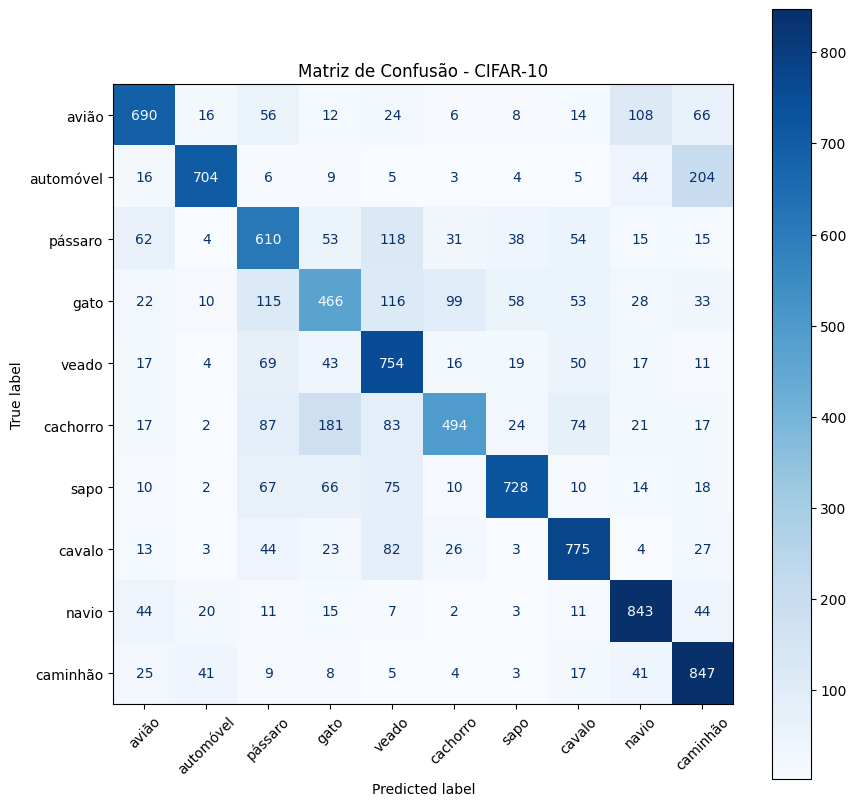

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test.flatten(),
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))

disp.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("Matriz de Confusão - CIFAR-10")
plt.show()

### 14. Análise dos resultados

Os resultados obtidos mostram que a CNN conseguiu aprender padrões relevantes para a classificação das imagens do conjunto CIFAR-10. Durante o treinamento, a acurácia no conjunto de treinamento aumentou de aproximadamente 45% na primeira época para 78% na décima época. No conjunto de validação, a acurácia atingiu aproximadamente 72%, indicando que o modelo conseguiu generalizar razoavelmente bem para imagens que não foram utilizadas diretamente no treinamento.

A melhor acurácia de validação foi de aproximadamente 71,6%, obtida na sétima época. Após esse ponto, a acurácia de treinamento continuou aumentando, enquanto a acurácia de validação permaneceu próxima de 71%. Esse comportamento indica um leve início de overfitting, pois o modelo continuou se ajustando aos dados de treinamento sem apresentar uma melhora significativa no conjunto de validação.

No conjunto de teste, o modelo apresentou **69,11% de acurácia**, com perda de **0,9171**. O resultado é próximo ao obtido na validação, indicando que o modelo apresenta uma capacidade de generalização razoável.

A matriz de confusão também permite observar diferenças entre as classes. As classes **navio, caminhão, cavalo e veado** apresentaram uma quantidade relativamente alta de classificações corretas. Por outro lado, **gato e cachorro** apresentaram maior dificuldade de diferenciação, com 181 imagens de cachorro classificadas como gato e 99 imagens de gato classificadas como cachorro.

Também houve confusão entre classes visualmente semelhantes, como **automóvel e caminhão**, sendo que 204 imagens de automóveis foram classificadas como caminhões. Além disso, algumas imagens de **aviões foram classificadas como navios**, o que também pode ocorrer devido às características visuais presentes nas imagens.

De maneira geral, os resultados mostram que a CNN foi capaz de realizar a classificação das imagens com desempenho satisfatório para a arquitetura utilizada, atingindo aproximadamente 69% de acurácia no conjunto de teste.

In [28]:
# Identifica os índices das classificações corretas e incorretas
y_true = y_test.flatten()

acertos = np.where(y_pred == y_true)[0]
erros = np.where(y_pred != y_true)[0]

print("Quantidade de classificações corretas:", len(acertos))
print("Quantidade de classificações incorretas:", len(erros))

Quantidade de classificações corretas: 6911
Quantidade de classificações incorretas: 3089


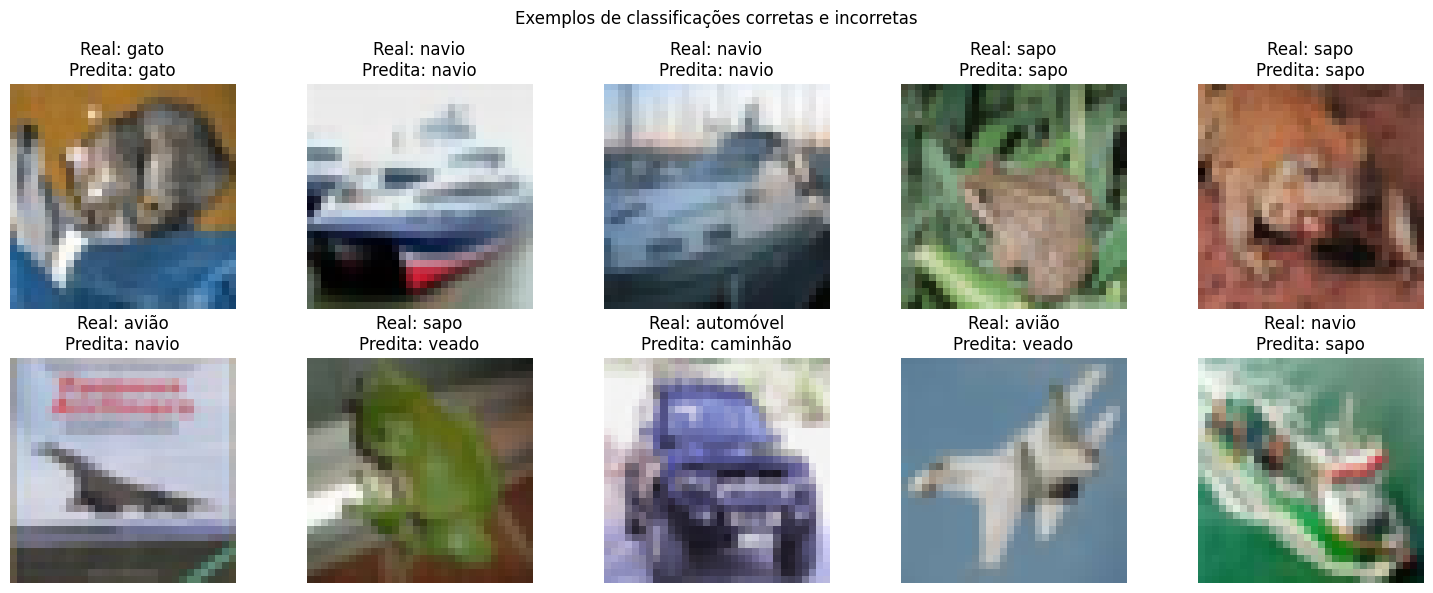

In [29]:
# Mostra exemplos de classificações corretas e incorretas

plt.figure(figsize=(15, 6))

for i in range(5):
    indice = acertos[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[indice])
    plt.title(
        f"Real: {class_names[y_true[indice]]}\n"
        f"Predita: {class_names[y_pred[indice]]}"
    )
    plt.axis("off")

for i in range(5):
    indice = erros[i]

    plt.subplot(2, 5, i + 6)
    plt.imshow(X_test[indice])
    plt.title(
        f"Real: {class_names[y_true[indice]]}\n"
        f"Predita: {class_names[y_pred[indice]]}"
    )
    plt.axis("off")

plt.suptitle("Exemplos de classificações corretas e incorretas")
plt.tight_layout()
plt.show()

### 15. Exemplos de classificações corretas e incorretas

Foram analisados exemplos de classificações corretas e incorretas realizadas pela CNN. No conjunto de teste, foram obtidas **6.911 classificações corretas e 3.089 classificações incorretas**, correspondendo à acurácia de 69,11%.

Entre os exemplos incorretos observados, ocorreram as seguintes classificações:

* avião → navio
* sapo → veado
* automóvel → caminhão
* avião → veado
* navio → sapo

Esses resultados mostram que algumas imagens apresentam características visuais que podem dificultar a classificação. A confusão entre avião e navio, por exemplo, pode ocorrer devido à presença de elementos visuais semelhantes, enquanto automóveis e caminhões também podem apresentar características próximas nas imagens.

Os exemplos analisados são coerentes com a matriz de confusão e ajudam a demonstrar, de forma visual, algumas das limitações do modelo.

### 16. Conclusão

Neste trabalho foi desenvolvida uma Rede Neural Convolucional (CNN) para classificação de imagens do conjunto de dados CIFAR-10. A arquitetura utilizada foi composta por duas etapas de convolução e pooling, seguidas por camadas densas responsáveis pela classificação das imagens em 10 categorias.

Durante o treinamento, foi possível observar uma evolução significativa da acurácia, atingindo **78,14% no conjunto de treinamento**. No conjunto de validação, a melhor acurácia foi de aproximadamente **71,6%**, indicando que o modelo conseguiu aprender características relevantes das imagens.

No conjunto de teste, a CNN apresentou **69,11% de acurácia** e perda de **0,9171**. A análise da matriz de confusão mostrou que algumas classes foram classificadas com maior facilidade, enquanto outras apresentaram maior confusão, principalmente classes visualmente semelhantes, como gato e cachorro e automóvel e caminhão.

Os resultados demonstram que a CNN foi capaz de realizar a classificação das imagens do CIFAR-10 de forma satisfatória para a arquitetura proposta, além de permitir analisar as principais dificuldades encontradas pelo modelo durante a classificação.